# 2. Experimento comparativo: clasificación de crecimiento ≥ 1% anual

## Diseño

| Paso | Datos | n |
|---|---|---|
| Entradas del entrenamiento | censos 1992 y 2002 | 314 comunas |
| Respuesta del entrenamiento | crecimiento 2002–2017 | 314 |
| Selección del modelo | validación cruzada estratificada de 5 particiones sobre el entrenamiento | 314 |
| Evaluación temporal (prueba) | entradas de 2002 y 2017, respuesta 2017–2024 | 314 |

El modelo se elige **solo con la validación cruzada** y luego se evalúa en un período futuro (2017–2024) que no se usó para entrenar. Las mismas 314 comunas aparecen en ambas etapas, pero cada etapa corresponde a un período distinto.

**Métrica principal: F1 macro**, que promedia el F1 de ambas clases con igual peso. Las clases están casi balanceadas (164 frente a 150 en la prueba), pero equivocarse en cualquiera de las dos importa, y la exactitud por sí sola podría premiar a un modelo que favorezca la clase mayoritaria. Como medidas complementarias se reportan la exactitud balanceada y la exactitud.

**Alternativas comparadas:** 10 configuraciones de Árbol de decisión, Random Forest y Regresión logística, con 3, 4 o 6 variables. Además hay dos líneas base: la clase mayoritaria y la *continuidad* (predecir que la comuna repite la clase del período anterior).

Las configuraciones se fijaron de antemano en `experiments/protocolo_crecimiento_v2.json`.

In [1]:

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
FIG = ROOT / 'results/entrega'
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

perfiles = pd.read_csv(ROOT / 'results/crecimiento_v2/perfiles_censales.csv')
calidad = json.loads((ROOT / 'results/crecimiento_v2/calidad_datos.json').read_text())
UMBRAL = 0.01

def tasa_anual(p0, p1, anios):
    return (np.asarray(p1, float) / np.asarray(p0, float)) ** (1 / anios) - 1

def anio(y):
    return perfiles[perfiles.year == y].set_index('code').sort_index()

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.inspection import permutation_importance
from sklearn.metrics import (f1_score, balanced_accuracy_score, accuracy_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)

protocolo = json.loads((ROOT / 'experiments/protocolo_crecimiento_v2.json').read_text())
CANDIDATOS = protocolo['alternatives']
NOMBRES = ['< 1% anual', '≥ 1% anual']
NUCLEO = sorted(set(anio(1992).index) & set(anio(2024).index) - {9101, 9112})
print('comunas del núcleo de comparación:', len(NUCLEO))

def entradas(prev, ini, codigos):
    a, b = anio(prev).loc[codigos], anio(ini).loc[codigos]
    t = ini - prev
    return pd.DataFrame({
        'log_poblacion': np.log1p(b.population),
        'proporcion_menores_15': b.young / b.population,
        'proporcion_65_mas': b.old / b.population,
        'crecimiento_previo': tasa_anual(a.population, b.population, t),
        'cambio_menores_15_anual': (b.young / b.population - a.young / a.population) / t,
        'cambio_65_mas_anual': (b.old / b.population - a.old / a.population) / t,
    }, index=codigos)

def respuesta(ini, fin, codigos):
    r = tasa_anual(anio(ini).loc[codigos].population, anio(fin).loc[codigos].population, fin - ini)
    return pd.Series((r >= UMBRAL).astype(int), index=codigos), pd.Series(r, index=codigos)

def modelo(c):
    clases = {'DecisionTreeClassifier': DecisionTreeClassifier, 'RandomForestClassifier': RandomForestClassifier,
              'LogisticRegression': LogisticRegression}
    cols = ColumnTransformer([('x', 'passthrough', c['features'])], remainder='drop')
    esc = StandardScaler() if c['algorithm'] == 'LogisticRegression' else 'passthrough'
    return Pipeline([('cols', cols), ('esc', esc), ('clf', clases[c['algorithm']](**c['params']))])

def metricas(y, p):
    return {'F1 macro': f1_score(y, p, average='macro'), 'exactitud balanceada': balanced_accuracy_score(y, p),
            'exactitud': accuracy_score(y, p), 'aciertos': int((np.asarray(y) == np.asarray(p)).sum()), 'n': len(y)}

X_tr = entradas(1992, 2002, NUCLEO); y_tr, r_tr = respuesta(2002, 2017, NUCLEO)
X_te = entradas(2002, 2017, NUCLEO); y_te, r_te = respuesta(2017, 2024, NUCLEO)
print('entrenamiento:', y_tr.value_counts().to_dict(), '| prueba:', y_te.value_counts().to_dict())

comunas del núcleo de comparación: 314
entrenamiento: {0: 217, 1: 97} | prueba: {0: 164, 1: 150}


## 2.1 Selección por validación cruzada (solo datos de entrenamiento)

El escalado de la regresión logística se ajusta **dentro** de cada partición mediante un `Pipeline`, para no filtrar información de la partición de validación. Criterio: mayor media de F1 macro por partición. Si hay empate, se prefiere mayor exactitud balanceada, luego menos variables y luego menor complejidad.

In [2]:
val = protocolo['validation']
folds = list(StratifiedKFold(n_splits=val['n_splits'], shuffle=val['shuffle'],
                             random_state=val['random_state']).split(X_tr, y_tr))
filas = []
for i, c in enumerate(CANDIDATOS):
    f1s, bas = [], []
    for tr, va in folds:
        p = modelo(c).fit(X_tr.iloc[tr], y_tr.iloc[tr]).predict(X_tr.iloc[va])
        f1s.append(f1_score(y_tr.iloc[va], p, average='macro')); bas.append(balanced_accuracy_score(y_tr.iloc[va], p))
    filas.append({'id': c['id'], 'algoritmo': c['algorithm'].replace('Classifier', ''), 'n_variables': len(c['features']),
                  'F1 macro (media CV)': np.mean(f1s), 'desv. est.': np.std(f1s, ddof=1),
                  'exactitud balanceada (media CV)': np.mean(bas), '_orden': (-len(c['features']), -c['complexity'], -i)})
# líneas base en CV
maj = np.zeros(len(y_tr), int)
for tr, va in folds: maj[va] = np.bincount(y_tr.iloc[tr]).argmax()
cont = (X_tr.crecimiento_previo >= UMBRAL).astype(int)
for nombre, p in [('mayoría (base)', maj), ('continuidad (base)', cont)]:
    filas.append({'id': nombre, 'algoritmo': 'línea base', 'n_variables': 0,
                  'F1 macro (media CV)': np.mean([f1_score(y_tr.iloc[va], np.asarray(p)[va], average='macro') for _, va in folds]),
                  'desv. est.': np.std([f1_score(y_tr.iloc[va], np.asarray(p)[va], average='macro') for _, va in folds], ddof=1),
                  'exactitud balanceada (media CV)': np.mean([balanced_accuracy_score(y_tr.iloc[va], np.asarray(p)[va]) for _, va in folds]),
                  '_orden': (0, 0, 0)})
cv = pd.DataFrame(filas)
modelos_cv = cv[cv.algoritmo != 'línea base']
ganador_id = max(modelos_cv.itertuples(), key=lambda r: (round(r[4], 12), round(r[6], 12), r[7])).id
ganador = next(c for c in CANDIDATOS if c['id'] == ganador_id)
print('Configuración seleccionada por CV:', ganador_id, '\n', ganador['params'], '\n', ganador['features'])
cv.drop(columns='_orden').sort_values('F1 macro (media CV)', ascending=False).round(3).reset_index(drop=True)

Configuración seleccionada por CV: bosque_tendencia 
 {'n_estimators': 300, 'max_depth': 5, 'min_samples_leaf': 8, 'class_weight': 'balanced_subsample', 'random_state': 2025, 'n_jobs': 2} 
 ['log_poblacion', 'proporcion_menores_15', 'proporcion_65_mas', 'crecimiento_previo']


,id,algoritmo,n_variables,F1 macro (media CV),desv. est.,exactitud balanceada (media CV)
0,bosque_tendencia,RandomForest,4,0.762,0.052,0.771
1,continuidad (base),línea base,0,0.759,0.045,0.781
2,logistica_tendencia,LogisticRegression,4,0.758,0.049,0.778
3,bosque_d5,RandomForest,6,0.748,0.029,0.759
4,arbol_d2,DecisionTree,6,0.729,0.053,0.749
5,arbol_tendencia,DecisionTree,4,0.729,0.019,0.765
6,arbol_d3,DecisionTree,6,0.718,0.021,0.745
7,logistica_c0.1,LogisticRegression,6,0.703,0.027,0.719
8,logistica_c1,LogisticRegression,6,0.697,0.029,0.714
9,logistica_c10,LogisticRegression,6,0.697,0.028,0.714


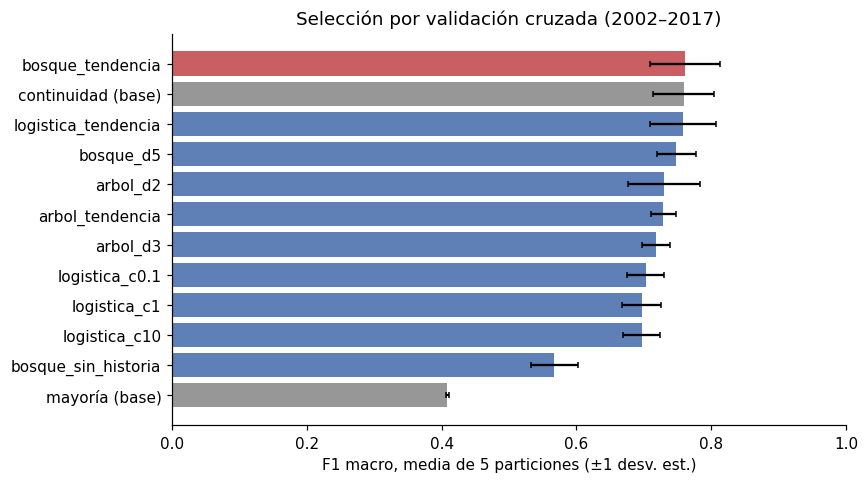

In [3]:
d = cv.sort_values('F1 macro (media CV)')
colores = ['#C44E52' if i == ganador_id else ('#8C8C8C' if a == 'línea base' else '#4C72B0') for i, a in zip(d.id, d.algoritmo)]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(d.id, d['F1 macro (media CV)'], xerr=d['desv. est.'], color=colores, alpha=.9, capsize=2)
ax.set_xlabel('F1 macro, media de 5 particiones (±1 desv. est.)'); ax.set_xlim(0, 1)
ax.set_title('Selección por validación cruzada (2002–2017)')
plt.tight_layout(); plt.savefig(FIG / 'exp_seleccion_cv.png', bbox_inches='tight'); plt.show()

**Lectura de la validación cruzada**
- **El crecimiento previo es la variable clave**: el Random Forest sin historia (`bosque_sin_historia`) cae a F1 ≈ 0,57, mientras que con historia (`bosque_tendencia`) sube a ≈ 0,76.
- Los cambios de proporciones etarias (6 variables) no mejoran a las variantes de 4 variables.
- Random Forest con 4 variables (0,762) y la logística con 4 variables (0,758) quedan prácticamente empatados, y la continuidad (0,759) también está muy cerca. Gana el Random Forest según el criterio fijado de antemano.

## 2.2 Evaluación temporal en 2017–2024

Se comparan en el período de prueba el modelo seleccionado, el mejor modelo de cada familia y las dos líneas base.

In [4]:
def mejor_de(alg):
    sub = modelos_cv[modelos_cv.algoritmo == alg]
    return sub.sort_values('F1 macro (media CV)', ascending=False).id.iloc[0]
comparar = [ganador_id] + [i for i in (mejor_de('LogisticRegression'), mejor_de('DecisionTree')) if i != ganador_id]
pred, res = {}, []
for cid in comparar:
    c = next(x for x in CANDIDATOS if x['id'] == cid)
    m = modelo(c).fit(X_tr, y_tr)
    pred[cid] = pd.Series(m.predict(X_te), index=NUCLEO)
    if cid == ganador_id: final = m
pred['continuidad (base)'] = (X_te.crecimiento_previo >= UMBRAL).astype(int)
pred['mayoría (base)'] = pd.Series(np.bincount(y_tr).argmax(), index=NUCLEO)
tabla = pd.DataFrame({k: metricas(y_te, p) for k, p in pred.items()}).T
tabla.round(3)

,F1 macro,exactitud balanceada,exactitud,aciertos,n
bosque_tendencia,0.642,0.662,0.653,205.0,314.0
logistica_tendencia,0.667,0.674,0.669,210.0,314.0
arbol_d2,0.442,0.554,0.535,168.0,314.0
continuidad (base),0.663,0.670,0.678,213.0,314.0
mayoría (base),0.343,0.500,0.522,164.0,314.0


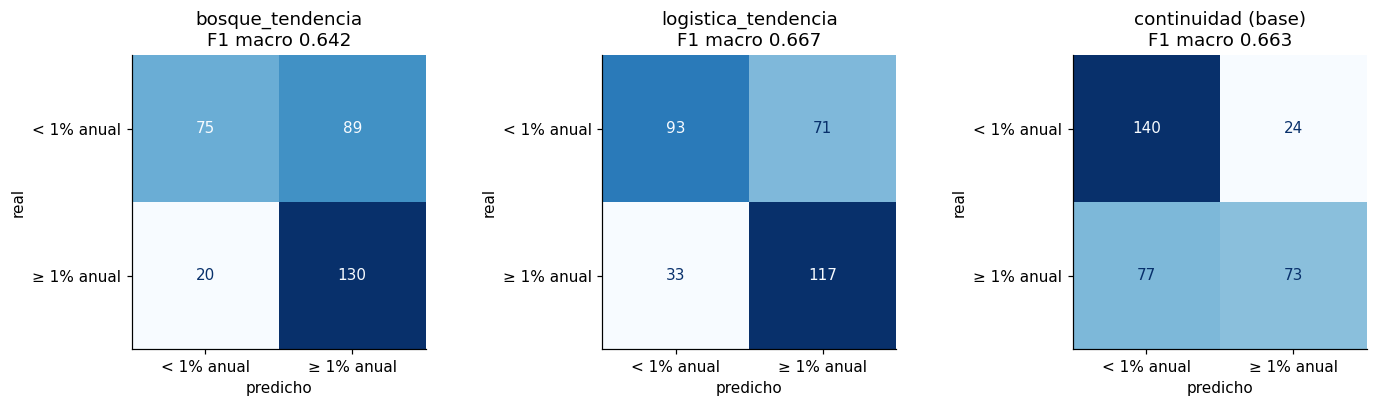

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, k in zip(axes, [ganador_id, comparar[1], 'continuidad (base)']):
    ConfusionMatrixDisplay(confusion_matrix(y_te, pred[k]), display_labels=NOMBRES).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'{k}\nF1 macro {f1_score(y_te, pred[k], average="macro"):.3f}')
    ax.set_xlabel('predicho'); ax.set_ylabel('real')
plt.tight_layout(); plt.savefig(FIG / 'exp_matrices_confusion.png', bbox_inches='tight'); plt.show()

### Resultados por clase

In [6]:
for k in [ganador_id, comparar[1], 'continuidad (base)']:
    print(f'=== {k} ===')
    print(classification_report(y_te, pred[k], target_names=NOMBRES, digits=3))

=== bosque_tendencia ===
              precision    recall  f1-score   support

  < 1% anual      0.789     0.457     0.579       164
  ≥ 1% anual      0.594     0.867     0.705       150

    accuracy                          0.653       314
   macro avg      0.692     0.662     0.642       314
weighted avg      0.696     0.653     0.639       314

=== logistica_tendencia ===
              precision    recall  f1-score   support

  < 1% anual      0.738     0.567     0.641       164
  ≥ 1% anual      0.622     0.780     0.692       150

    accuracy                          0.669       314
   macro avg      0.680     0.674     0.667       314
weighted avg      0.683     0.669     0.666       314

=== continuidad (base) ===
              precision    recall  f1-score   support

  < 1% anual      0.645     0.854     0.735       164
  ≥ 1% anual      0.753     0.487     0.591       150

    accuracy                          0.678       314
   macro avg      0.699     0.670     0.663     

## 2.3 Importancia de las variables del modelo seleccionado

Importancia por permutación en el período de prueba: cuánto cae el F1 macro si se desordena cada variable.

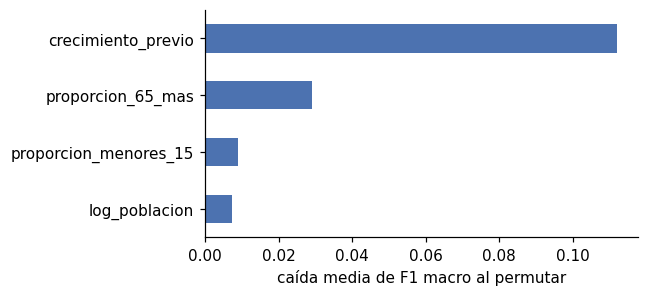

In [7]:
imp = permutation_importance(final, X_te, y_te, scoring='f1_macro', n_repeats=30, random_state=2025)
imp = pd.Series(imp.importances_mean, index=X_te.columns).loc[ganador['features']].sort_values()
ax = imp.plot.barh(figsize=(6, 2.8), color='#4C72B0'); ax.set_xlabel('caída media de F1 macro al permutar')
plt.tight_layout(); plt.savefig(FIG / 'exp_importancia.png', bbox_inches='tight'); plt.show()

## 2.4 Análisis de errores del modelo seleccionado

In [8]:
err = pd.DataFrame({'comuna': anio(2017).loc[NUCLEO, 'name'], 'region': anio(2017).loc[NUCLEO, 'region'],
                    'poblacion_2017': anio(2017).loc[NUCLEO, 'population'],
                    'tasa_previa_%': 100 * X_te.crecimiento_previo, 'tasa_real_%': 100 * r_te,
                    'real': y_te, 'predicho': pred[ganador_id],
                    'score': final.predict_proba(X_te)[:, 1]}, index=NUCLEO)
err['tipo'] = np.select([(err.real == 1) & (err.predicho == 1), (err.real == 0) & (err.predicho == 0),
                         (err.real == 0) & (err.predicho == 1)], ['VP', 'VN', 'FP (falsa alerta)'], 'FN (omitida)')
display(err.tipo.value_counts().to_frame('comunas'))
err['dist_umbral_pp'] = (err['tasa_real_%'] - 1).abs()
print('Mediana de distancia al umbral (puntos porcentuales), según acierto:')
display(err.assign(acierto=err.real == err.predicho).groupby('acierto').dist_umbral_pp.median().round(2))
print('Falsas alertas con mayor score (el modelo esperaba crecimiento alto y no ocurrió):')
display(err[err.tipo == 'FP (falsa alerta)'].sort_values('score', ascending=False).head(8).round(2))
print('Crecimientos altos omitidos:')
display(err[err.tipo == 'FN (omitida)'].sort_values('score').round(2))

,comunas
tipo,
VP,130
FP (falsa alerta),89
VN,75
FN (omitida),20


Mediana de distancia al umbral (puntos porcentuales), según acierto:


acierto
False    0.51
True     0.69
Name: dist_umbral_pp, dtype: float64

Falsas alertas con mayor score (el modelo esperaba crecimiento alto y no ocurrió):


,comuna,region,poblacion_2017,tasa_previa_%,tasa_real_%,real,predicho,score,tipo,dist_umbral_pp
12301,Porvenir,Magallanes y de la Antártica Chilena,6652,2.07,0.33,0,1,0.87,FP (falsa alerta),0.67
13403,Calera de Tango,Metropolitana de Santiago,25230,2.22,0.15,0,1,0.86,FP (falsa alerta),0.85
13303,Tiltil,Metropolitana de Santiago,18769,1.69,0.72,0,1,0.82,FP (falsa alerta),0.28
13107,Huechuraba,Metropolitana de Santiago,97829,1.88,0.57,0,1,0.82,FP (falsa alerta),0.43
13602,El Monte,Metropolitana de Santiago,35552,1.96,0.76,0,1,0.81,FP (falsa alerta),0.24
5104,Juan Fernández,Valparaíso,920,2.65,-0.25,0,1,0.81,FP (falsa alerta),1.25
5201,Isla de Pascua,Valparaíso,7096,4.32,-5.43,0,1,0.80,FP (falsa alerta),6.43
15201,Putre,Arica y Parinacota,2213,1.89,-4.99,0,1,0.80,FP (falsa alerta),5.99


Crecimientos altos omitidos:


,comuna,region,poblacion_2017,tasa_previa_%,tasa_real_%,real,predicho,score,tipo,dist_umbral_pp
10403,Hualaihué,Los Lagos,8804,0.47,1.06,1,0,0.24,FN (omitida),0.06
14202,Futrono,Los Ríos,14414,-0.22,1.17,1,0,0.26,FN (omitida),0.17
9104,Curarrehue,La Araucanía,7171,0.35,1.08,1,0,0.26,FN (omitida),0.08
10201,Castro,Los Lagos,43024,0.60,1.27,1,0,0.35,FN (omitida),0.27
1404,Huara,Tarapacá,2533,0.03,1.74,1,0,0.39,FN (omitida),0.74
16302,Coihueco,Ñuble,26442,0.77,1.71,1,0,0.40,FN (omitida),0.71
7408,Yerbas Buenas,Maule,17753,0.71,1.74,1,0,0.40,FN (omitida),0.74
5503,Hijuelas,Valparaíso,17902,0.77,1.07,1,0,0.41,FN (omitida),0.07
8303,Cabrero,Biobío,28404,0.79,1.38,1,0,0.45,FN (omitida),0.38
9108,Lautaro,La Araucanía,37344,0.99,1.67,1,0,0.46,FN (omitida),0.67


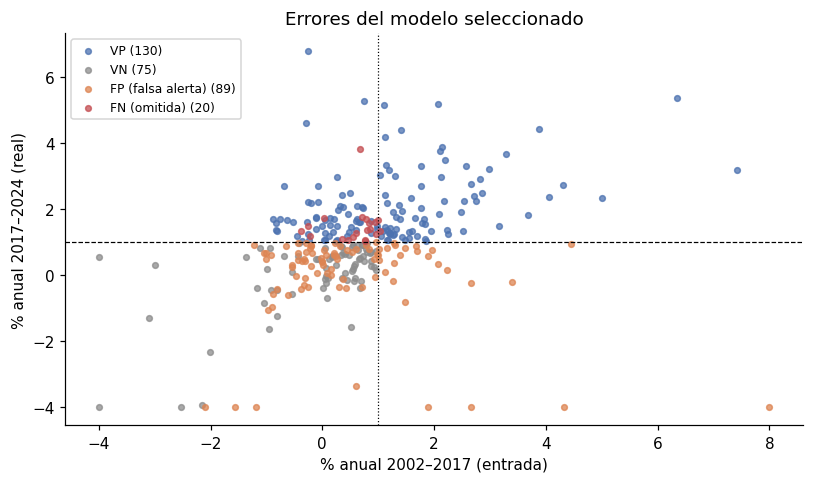

Falsas alertas por región (top 6):


region
Metropolitana de Santiago                20
Los Lagos                                12
Valparaíso                                9
Libertador General Bernardo O'Higgins     7
Biobío                                    7
La Araucanía                              6
Name: count, dtype: int64

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for t, c in [('VP', '#4C72B0'), ('VN', '#8C8C8C'), ('FP (falsa alerta)', '#DD8452'), ('FN (omitida)', '#C44E52')]:
    d = err[err.tipo == t]
    ax.scatter(d['tasa_previa_%'].clip(-4, 8), d['tasa_real_%'].clip(-4, 8), s=14, c=c, label=f'{t} ({len(d)})', alpha=.75)
ax.axhline(1, color='k', lw=.8, ls='--'); ax.axvline(1, color='k', lw=.8, ls=':')
ax.set_xlabel('% anual 2002–2017 (entrada)'); ax.set_ylabel('% anual 2017–2024 (real)')
ax.set_title('Errores del modelo seleccionado'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / 'exp_errores.png', bbox_inches='tight'); plt.show()
print('Falsas alertas por región (top 6):'); display(err[err.tipo == 'FP (falsa alerta)'].region.value_counts().head(6))

**Qué muestran los errores**
- Los errores tienden a estar **más cerca del umbral** que los aciertos (mediana de 0,51 contra 0,69 puntos porcentuales de distancia a 1%). Parte del error es inevitable con un corte binario.
- **89 de los 109 errores son falsas alertas.** De ellas:
  - **62 crecieron, pero por debajo del umbral** (entre 0 y 1% anual), y **27 perdieron población**. Entre estas últimas hay comunas pequeñas o aisladas con caídas fuertes que la historia no anticipaba (Isla de Pascua, Putre, Juan Fernández).
  - Solo **24** venían creciendo ≥1% en 2002–2017 y se desaceleraron, por ejemplo Calera de Tango, Huechuraba, El Monte y Tiltil, en la periferia de Santiago (la RM aporta 20 falsas alertas en total). Las otras 65 venían creciendo menos de 1%, y el modelo igual las clasificó como positivas.
- Las **20 omisiones** son, en su mayoría, comunas del centro-sur (Los Lagos, La Araucanía, Ñuble, Maule) que antes crecían menos de 1% y pasaron a superarlo por poco (1,0–1,7%). Es el desplazamiento regional que se vio en el EDA.
- Además, el modelo marca como positivas más comunas de las que lo eran en el entrenamiento (219 predicciones positivas contra 31% de positivos en 2002–2017). Eso se debe a los pesos de clase balanceados: favorecen el recall de la clase minoritaria a costa de su precisión.

## 2.5 Selección y justificación

In [10]:
g, c = tabla.loc[ganador_id], tabla.loc['continuidad (base)']
fn = lambda k: int(((y_te == 1) & (pred[k] == 0)).sum()); fp = lambda k: int(((y_te == 0) & (pred[k] == 1)).sum())
resumen = pd.DataFrame({
    ganador_id: [g['F1 macro'], g['aciertos'], int(((y_te == 1) & (pred[ganador_id] == 1)).sum()), fn(ganador_id), fp(ganador_id)],
    'continuidad (base)': [c['F1 macro'], c['aciertos'], int(((y_te == 1) & (pred['continuidad (base)'] == 1)).sum()), fn('continuidad (base)'), fp('continuidad (base)')],
}, index=['F1 macro', 'aciertos / 314', 'crecimientos altos detectados (de 150)', 'crecimientos altos omitidos', 'falsas alertas'])
display(resumen.round(3))
# intervalo exploratorio por remuestreo de comunas para la diferencia de F1 macro
rng = np.random.default_rng(2025); difs = []
yy, pm, pc = y_te.to_numpy(), pred[ganador_id].to_numpy(), pred['continuidad (base)'].to_numpy()
for _ in range(2000):
    i = rng.integers(0, len(yy), len(yy))
    difs.append(f1_score(yy[i], pm[i], average='macro') - f1_score(yy[i], pc[i], average='macro'))
print(f'Diferencia F1 macro (modelo − continuidad): {g["F1 macro"] - c["F1 macro"]:+.3f}; '
      f'IC 95% bootstrap [{np.percentile(difs, 2.5):+.3f}; {np.percentile(difs, 97.5):+.3f}]')

,bosque_tendencia,continuidad (base)
F1 macro,0.642,0.663
aciertos / 314,205.000,213.000
crecimientos altos detectados (de 150),130.000,73.000
crecimientos altos omitidos,20.000,77.000
falsas alertas,89.000,24.000


Diferencia F1 macro (modelo − continuidad): -0.021; IC 95% bootstrap [-0.087; +0.046]


**Modelo seleccionado: Random Forest** (`bosque_tendencia`) con 300 árboles, profundidad máxima 5, mínimo 8 ejemplos por hoja y pesos de clase balanceados. Usa 4 variables: log de la población, proporción de menores de 15, proporción de 65 o más y crecimiento previo.

**Justificación**
1. **Fue el mejor en la validación cruzada** (F1 macro ≈ 0,76), que es el criterio fijado antes de mirar la prueba. Supera a los árboles de decisión, a la logística con 6 variables y a su propia versión sin historia.
2. **En la prueba temporal 2017–2024** obtiene F1 macro 0,642 (205/314 aciertos). Supera con amplitud al árbol (0,442) y a la clase mayoritaria (0,343). La logística de 4 variables obtiene un valor algo mayor (0,667), y la continuidad, 0,663.
3. **Las diferencias entre los tres mejores no son concluyentes.** Frente a la continuidad, el intervalo bootstrap de la diferencia de F1 macro incluye el cero. Cambiar ahora a la logística porque ganó en la prueba sería elegir el modelo *con los datos de prueba*, y la evaluación dejaría de ser válida; por eso se mantiene la elección por validación cruzada. Lo que sí distingue claramente a los modelos es el *tipo de error*: el Random Forest detecta **130 de las 150** comunas de crecimiento alto (recall 0,87), contra 117 de la logística (0,78) y 73 de la continuidad (0,49), a cambio de más falsas alertas.
4. Para el uso que motiva el proyecto (identificar comunas que podrían necesitar planificar más vivienda, servicios o transporte), **omitir una comuna que sí crece es más costoso** que revisar una falsa alerta. Por eso se prefiere el Random Forest, que además ofrece un score continuo para priorizar la revisión.

**Limitaciones**
- Solo hay **un período para entrenar** y uno para evaluar, y el cambio de ritmo de crecimiento entre ambos genera la mayoría de las falsas alertas.
- La validación cruzada es *entre comunas* de un mismo período, no entre períodos futuros.
- 2024 ya se había observado en una versión anterior del proyecto (v1). Esta evaluación es una **reevaluación temporal exploratoria**, no una prueba ciega nueva.
- El score del modelo no está calibrado y no debe leerse como una probabilidad.